In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
d = pd.read_csv("waterquality.csv", sep=";")

In [3]:
print(d.shape)

(900, 5)


In [4]:
print(d.head())

   ID  river_section  saison  nitrate_mgL  oxygen_mgL
0   1  A1_headwaters  spring        5.540      10.711
1   2  A1_headwaters  spring        3.328       9.937
2   3  A1_headwaters  spring        5.742      10.499
3   4  A1_headwaters  spring        7.822      10.405
4   5  A1_headwaters  spring        8.843      10.245


In [5]:
print(d.dtypes)

ID                 int64
river_section        str
saison               str
nitrate_mgL      float64
oxygen_mgL       float64
dtype: object


In [6]:
print(d.isna().sum())

ID               0
river_section    0
saison           0
nitrate_mgL      0
oxygen_mgL       0
dtype: int64


In [7]:
print(d["river_section"].value_counts())

river_section
A1_headwaters       180
A2_upper_course     180
A3_middle_course    180
A4_lower_course     180
A5_mouth            180
Name: count, dtype: int64


In [8]:
print(d["saison"].value_counts())

saison
spring    225
summer    225
autumn    225
winter    225
Name: count, dtype: int64


In [9]:
print(pd.crosstab(d["river_section"], d["saison"]))

saison            autumn  spring  summer  winter
river_section                                   
A1_headwaters         45      45      45      45
A2_upper_course       45      45      45      45
A3_middle_course      45      45      45      45
A4_lower_course       45      45      45      45
A5_mouth              45      45      45      45


In [10]:
def summary(g):
    return pd.Series({
        "n": g.count(), "mean": g.mean(), "median": g.median(),
        "sd": g.std(), "q1": g.quantile(0.25), "q3": g.quantile(0.75),
        "min": g.min(), "max": g.max()})

In [11]:
for var in ["nitrate_mgL", "oxygen_mgL"]:
    print(var, "by season")
    print(d.groupby("saison")[var].apply(summary).unstack().round(2))
    print(var, "by section")
    print(d.groupby("river_section")[var].apply(summary).unstack().round(2))

nitrate_mgL by season
            n   mean  median    sd    q1     q3   min    max
saison                                                      
autumn  225.0   8.42    8.57  2.75  6.63  10.51  2.00  16.38
spring  225.0   9.29    9.65  2.59  7.18  11.22  1.51  14.79
summer  225.0  10.34   10.71  2.74  8.36  12.52  3.96  16.44
winter  225.0   7.20    7.55  2.44  5.29   8.94  1.56  13.21
nitrate_mgL by section
                      n   mean  median    sd     q1     q3   min    max
river_section                                                          
A1_headwaters     180.0   5.35    5.35  1.71   4.03   6.66  1.51  11.05
A2_upper_course   180.0   7.34    7.22  1.79   6.27   8.59  3.73  12.36
A3_middle_course  180.0   9.33    9.49  1.81   8.00  10.64  4.06  13.10
A4_lower_course   180.0  10.57   10.45  1.86   9.22  12.09  6.33  15.36
A5_mouth          180.0  11.47   11.40  1.98  10.17  13.01  6.64  16.44
oxygen_mgL by season
            n  mean  median    sd    q1     q3   min    max
sais

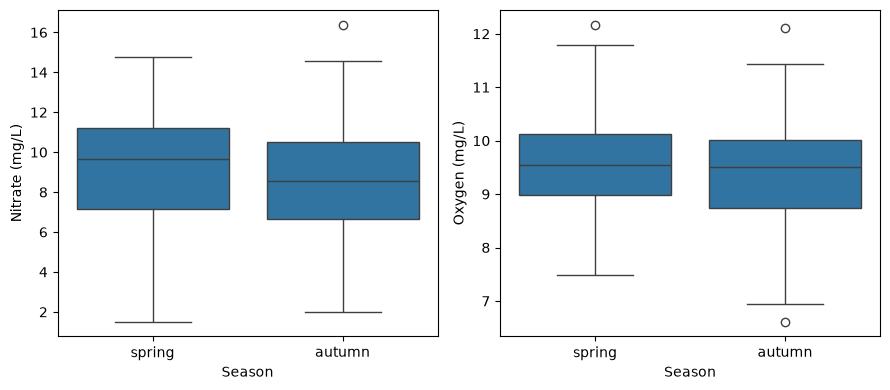

In [12]:
order_sec = ["A1_headwaters","A2_upper_course","A3_middle_course","A4_lower_course","A5_mouth"]

sub = d[d["saison"].isin(["spring","autumn"])]
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
sns.boxplot(data=sub, x="saison", y="nitrate_mgL", order=["spring","autumn"], ax=ax[0])
sns.boxplot(data=sub, x="saison", y="oxygen_mgL", order=["spring","autumn"], ax=ax[1])
ax[0].set_xlabel("Season"); ax[0].set_ylabel("Nitrate (mg/L)")
ax[1].set_xlabel("Season"); ax[1].set_ylabel("Oxygen (mg/L)")
plt.tight_layout()
plt.savefig("fig_season.pdf")
plt.show()

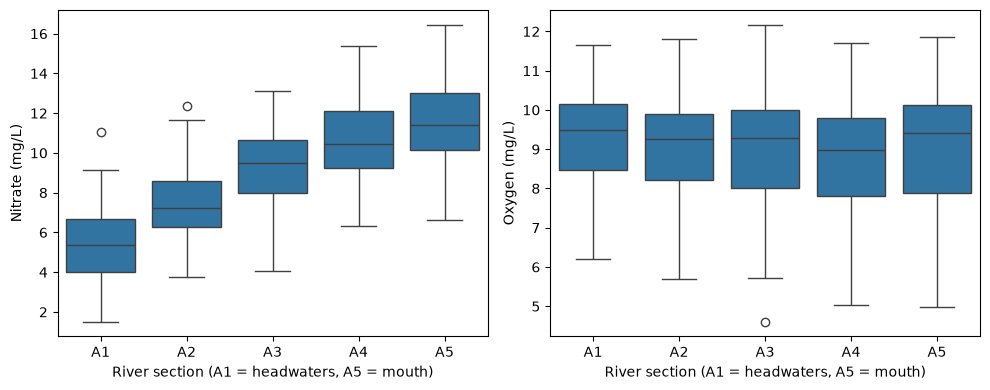

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=d, x="river_section", y="nitrate_mgL", order=order_sec, ax=ax[0])
sns.boxplot(data=d, x="river_section", y="oxygen_mgL", order=order_sec, ax=ax[1])
for a, name in zip(ax, ["Nitrate (mg/L)", "Oxygen (mg/L)"]):
    a.set_xticks(range(5)); a.set_xticklabels(["A1","A2","A3","A4","A5"])
    a.set_xlabel("River section (A1 = headwaters, A5 = mouth)")
    a.set_ylabel(name)
plt.tight_layout()
plt.savefig("fig_section.pdf")
plt.show()

In [14]:
import scipy.stats as st

rows = []
for var in ["nitrate_mgL", "oxygen_mgL"]:
    sp_ = d[d.saison=="spring"][var]; au = d[d.saison=="autumn"][var]
    rows.append([var, "spring", round(st.shapiro(sp_).pvalue, 4)])
    rows.append([var, "autumn", round(st.shapiro(au).pvalue, 4)])
    rows.append([var, "spring vs autumn variance (Levene)", round(st.levene(sp_, au).pvalue, 4)])
    for s in order_sec:
        rows.append([var, s, round(st.shapiro(d[d.river_section==s][var]).pvalue, 4)])
    groups = [d[d.river_section==s][var] for s in order_sec]
    rows.append([var, "5 sections variance (Levene)", round(st.levene(*groups).pvalue, 4)])

check = pd.DataFrame(rows, columns=["variable", "group / test", "p-value"])
print(check.to_string(index=False))

   variable                       group / test  p-value
nitrate_mgL                             spring   0.0206
nitrate_mgL                             autumn   0.0179
nitrate_mgL spring vs autumn variance (Levene)   0.2123
nitrate_mgL                      A1_headwaters   0.2129
nitrate_mgL                    A2_upper_course   0.1226
nitrate_mgL                   A3_middle_course   0.0822
nitrate_mgL                    A4_lower_course   0.1368
nitrate_mgL                           A5_mouth   0.3246
nitrate_mgL       5 sections variance (Levene)   0.3566
 oxygen_mgL                             spring   0.5144
 oxygen_mgL                             autumn   0.0891
 oxygen_mgL spring vs autumn variance (Levene)   0.4160
 oxygen_mgL                      A1_headwaters   0.0013
 oxygen_mgL                    A2_upper_course   0.0001
 oxygen_mgL                   A3_middle_course   0.0004
 oxygen_mgL                    A4_lower_course   0.0000
 oxygen_mgL                           A5_mouth  

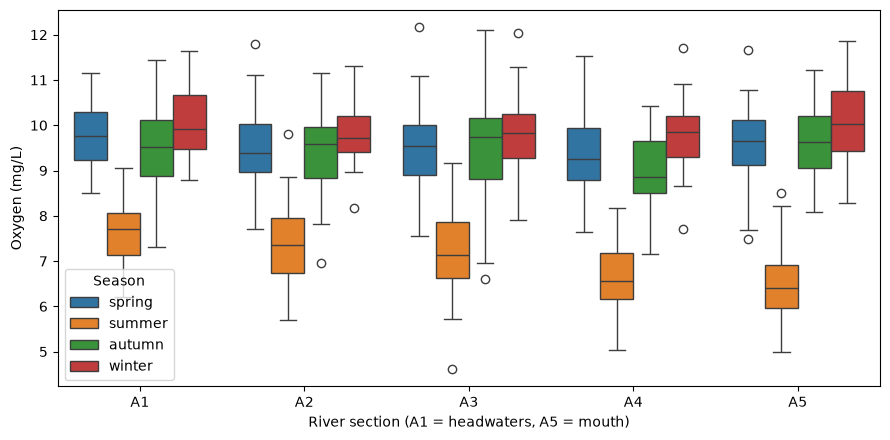

In [15]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=d, x="river_section", y="oxygen_mgL", hue="saison", order=order_sec)
plt.xticks(range(5), ["A1","A2","A3","A4","A5"])
plt.xlabel("River section (A1 = headwaters, A5 = mouth)")
plt.ylabel("Oxygen (mg/L)")
plt.legend(title="Season")
plt.tight_layout(); plt.savefig("fig_oxygen_hue.pdf"); plt.show()

In [16]:
a = d[d.saison=="spring"]["nitrate_mgL"]
b = d[d.saison=="autumn"]["nitrate_mgL"]
res = st.ttest_ind(a, b, equal_var=False)
print("t =", round(res.statistic, 3))
print("df =", round(res.df, 1))
print("p =", res.pvalue)

t = 3.455
df = 446.4
p = 0.0006023740175261007


In [17]:
sp_ = np.sqrt((a.var() + b.var()) / 2)
print("Cohen d =", round((a.mean() - b.mean()) / sp_, 2))

Cohen d = 0.33


In [18]:
a2 = d[d.saison=="spring"]["oxygen_mgL"]
b2 = d[d.saison=="autumn"]["oxygen_mgL"]
res2 = st.ttest_ind(a2, b2, equal_var=False)
print("t =", round(res2.statistic, 3))
print("df =", round(res2.df, 1))
print("p =", round(res2.pvalue, 4))
sp2 = np.sqrt((a2.var() + b2.var()) / 2)
print("Cohen d =", round((a2.mean() - b2.mean()) / sp2, 2))

t = 1.847
df = 447.4
p = 0.0654
Cohen d = 0.17


In [19]:
for var in ["nitrate_mgL", "oxygen_mgL"]:
    a = d[d.saison=="spring"][var]
    b = d[d.saison=="autumn"][var]
    r = st.mannwhitneyu(a, b, alternative="two-sided")
    print(var, "U =", r.statistic, " p =", round(r.pvalue, 4))

nitrate_mgL U = 29947.5  p = 0.0008
oxygen_mgL U = 27420.0  p = 0.1266


In [20]:
g = [d[d.river_section==s]["nitrate_mgL"] for s in order_sec]
res = st.f_oneway(*g)
print("F =", round(res.statistic, 2), "  p =", res.pvalue)

allv = np.concatenate(g); gm = allv.mean()
ssb = sum(len(x)*(x.mean()-gm)**2 for x in g)
sst = ((allv-gm)**2).sum()
print("SS_between =", round(ssb, 1), "  SS_within =", round(sst-ssb, 1))
print("eta squared =", round(ssb/sst, 3))

F = 329.1   p = 4.246425146083931e-174
SS_between = 4418.1   SS_within = 3003.8
eta squared = 0.595


In [21]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tuk = pairwise_tukeyhsd(d["nitrate_mgL"], d["river_section"], alpha=0.05)
print(tuk)

         Multiple Comparison of Means - Tukey HSD, FWER=0.05         
     group1           group2      meandiff p-adj lower  upper  reject
---------------------------------------------------------------------
   A1_headwaters  A2_upper_course   1.9925   0.0 1.4647 2.5204   True
   A1_headwaters A3_middle_course    3.978   0.0 3.4502 4.5058   True
   A1_headwaters  A4_lower_course   5.2196   0.0 4.6918 5.7475   True
   A1_headwaters         A5_mouth   6.1162   0.0 5.5884  6.644   True
 A2_upper_course A3_middle_course   1.9855   0.0 1.4576 2.5133   True
 A2_upper_course  A4_lower_course   3.2271   0.0 2.6993 3.7549   True
 A2_upper_course         A5_mouth   4.1236   0.0 3.5958 4.6515   True
A3_middle_course  A4_lower_course   1.2416   0.0 0.7138 1.7695   True
A3_middle_course         A5_mouth   2.1382   0.0 1.6103  2.666   True
 A4_lower_course         A5_mouth   0.8965   0.0 0.3687 1.4244   True
---------------------------------------------------------------------


In [23]:
g = [d[d.river_section==s]["oxygen_mgL"] for s in order_sec]
res = st.kruskal(*g)
print("H =", round(res.statistic, 2), "  df = 4   p =", res.pvalue)

import scikit_posthocs as sp
dunn = sp.posthoc_dunn(d, val_col="oxygen_mgL", group_col="river_section", p_adjust="holm")
print(dunn.round(4))

print(d.groupby("river_section")["oxygen_mgL"].median().round(2))

H = 11.65   df = 4   p = 0.02019496054213179
                  A1_headwaters  A2_upper_course  A3_middle_course  \
A1_headwaters            1.0000           0.7048            0.7276   
A2_upper_course          0.7048           1.0000            1.0000   
A3_middle_course         0.7276           1.0000            1.0000   
A4_lower_course          0.0079           0.5151            0.4604   
A5_mouth                 1.0000           1.0000            1.0000   

                  A4_lower_course  A5_mouth  
A1_headwaters              0.0079    1.0000  
A2_upper_course            0.5151    1.0000  
A3_middle_course           0.4604    1.0000  
A4_lower_course            1.0000    0.2437  
A5_mouth                   0.2437    1.0000  
river_section
A1_headwaters       9.50
A2_upper_course     9.26
A3_middle_course    9.28
A4_lower_course     8.99
A5_mouth            9.42
Name: oxygen_mgL, dtype: float64
